<a href="https://colab.research.google.com/github/Rickylel/AF1_Analisis_Exploratorio_y_Preprocesamiento_de_Datos_-EDA-/blob/main/AF1_Analisis_Exploratorio_y_Preprocesamiento_de_Datos_(EDA).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis Exploratorio y Preprocesamiento de Datos (EDA)
## Sección 1: Carga e Inspección Inicial con `pandas`
**Dataset:** Stroke Prediction Dataset (Kaggle)

**Objetivo:** Familiarizarse con la estructura del dataset, identificar tipos de datos y detectar anomalías iniciales.

### 1. Carga del dataset en un DataFrame
En Colab, subimos el archivo `healthcare-dataset-stroke-data.csv` para poder cargar el dataframe con los datos

In [1]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)  # mostrar todas las columnas
pd.set_option('display.width', 200)

RUTA = 'healthcare-dataset-stroke-data.csv'

# Si estás en Colab y el archivo no está, se abre el diálogo para subirlo
try:
    from google.colab import files  # solo existe en Colab
    import os
    if not os.path.exists(RUTA):
        subido = files.upload()
        RUTA = list(subido.keys())[0]
except ImportError:
    pass

df = pd.read_csv(RUTA)
print(f'Dataset cargado: {df.shape[0]} filas x {df.shape[1]} columnas')

Dataset cargado: 5110 filas x 12 columnas


### 2. Primeras y últimas 5 filas

In [2]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
df.tail()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


### 3. Información general (`info()`)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [5]:
# Resumen de tipos de datos por columna
df.dtypes.value_counts()

,count
object,5
int64,4
float64,3


### 4. Resumen estadístico de variables numéricas (`describe()`)

In [6]:
df.describe().round(2)

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.00,5110.00,5110.0,5110.00,5110.00,4909.00,5110.00
mean,36517.83,43.23,0.1,0.05,106.15,28.89,0.05
std,21161.72,22.61,0.3,0.23,45.28,7.85,0.22
min,67.00,0.08,0.0,0.00,55.12,10.30,0.00
25%,17741.25,25.00,0.0,0.00,77.24,23.50,0.00
50%,36932.00,45.00,0.0,0.00,91.88,28.10,0.00
75%,54682.00,61.00,0.0,0.00,114.09,33.10,0.00
max,72940.00,82.00,1.0,1.00,271.74,97.60,1.00


In [7]:
# Complemento: resumen de las variables categóricas
df.describe(include='object')

,gender,ever_married,work_type,Residence_type,smoking_status
count,5110,5110,5110,5110,5110
unique,3,2,5,2,4
top,Female,Yes,Private,Urban,never smoked
freq,2994,3353,2925,2596,1892


### 5. Detección de valores nulos (`isnull().sum()`)

In [8]:
nulos = df.isnull().sum()
pct = (nulos / len(df) * 100).round(2)
pd.DataFrame({'nulos': nulos, '% del total': pct}).sort_values('nulos', ascending=False)

,nulos,% del total
bmi,201,3.93
id,0,0.00
age,0,0.00
gender,0,0.00
hypertension,0,0.00
heart_disease,0,0.00
work_type,0,0.00
ever_married,0,0.00
Residence_type,0,0.00
avg_glucose_level,0,0.00


#### Revisión extra de anomalías
`isnull()` solo detecta `NaN`. Conviene revisar también valores que *representan* datos faltantes o raros dentro de las categóricas, y duplicados.

In [9]:
for col in df.select_dtypes(include='object').columns:
    print(f'--- {col} ---')
    print(df[col].value_counts(), '\n')

--- gender ---
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64 

--- ever_married ---
ever_married
Yes    3353
No     1757
Name: count, dtype: int64 

--- work_type ---
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64 

--- Residence_type ---
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64 

--- smoking_status ---
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64 



In [10]:
print('Filas duplicadas:', df.duplicated().sum())
print('IDs duplicados  :', df['id'].duplicated().sum())
print('\nProporción de la variable objetivo (stroke):')
print(df['stroke'].value_counts(normalize=True).mul(100).round(2))

Filas duplicadas: 0
IDs duplicados  : 0

Proporción de la variable objetivo (stroke):
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


### Conclusiones de la Sección 1

- **Estructura:** 5,110 registros y 12 columnas. Tipos: 3 `float64` (`age`, `avg_glucose_level`, `bmi`), 4 `int64` (`id`, `hypertension`, `heart_disease`, `stroke`) y 5 `object` (`gender`, `ever_married`, `work_type`, `Residence_type`, `smoking_status`).
- **Valores nulos:** solo `bmi` tiene faltantes: **201 registros (≈3.93 %)**. Habrá que imputarlos (p. ej. con la mediana) en la etapa de limpieza.
- **Faltantes “ocultos”:** `smoking_status` tiene **1,544 registros como `"Unknown"`** (≈30 %). No aparecen en `isnull()`, pero en la práctica son datos desconocidos.
- **Categoría rara:** `gender` tiene **1 solo registro `"Other"`**; es candidato a eliminarse porque no aporta información estadística.
- **Estadísticas destacables:**
  - `age` va de **0.08 a 82 años** (media ≈ 43.2): hay bebés, por eso hay edades decimales.
  - `avg_glucose_level` tiene media 106.15 pero máximo 271.74 → distribución sesgada a la derecha, posibles outliers.
  - `bmi` llega a **97.6**, valor extremo poco realista → outlier a revisar.
  - `hypertension` y `heart_disease` son binarias (0/1) aunque se guarden como `int64`.
- **Desbalance de clases:** solo el **4.87 %** de los registros tiene `stroke = 1`. Importante para el modelado (métricas, sobremuestreo, etc.).
- **Duplicados:** no hay filas ni `id` duplicados. La columna `id` es solo un identificador y no sirve como variable predictora.


---
# Sección 2: Limpieza, Transformación y Tratamiento con `pandas` y `numpy`
Objetivo: tomar decisiones de ingeniería de datos para limpiar el dataset, tratar nulos y codificar variables categóricas.

In [11]:
# Trabajamos sobre una copia para conservar el DataFrame original intacto
df_clean = df.copy()
df_clean.shape

(5110, 12)

### 1. Tratamiento de nulos: imputación de `bmi` con la mediana
Se usa la **mediana** y no la media porque `bmi` tiene outliers (máx. 97.6) y la mediana es robusta a valores extremos.

In [12]:
mediana_bmi = np.nanmedian(df_clean['bmi'])   # mediana ignorando NaN
print(f'Mediana de bmi: {mediana_bmi}')
print(f'Nulos antes : {df_clean["bmi"].isnull().sum()}')

df_clean['bmi'] = df_clean['bmi'].fillna(mediana_bmi)

print(f'Nulos después: {df_clean["bmi"].isnull().sum()}')

Mediana de bmi: 28.1
Nulos antes : 201
Nulos después: 0


In [13]:
df_clean.isnull().sum().sum()  # total de nulos en todo el dataset

np.int64(0)

### 2. Detección de valores atípicos con el método IQR (`numpy`)
- $Q1$ = percentil 25, $Q3$ = percentil 75
- $IQR = Q3 - Q1$
- Límite inferior: $Q1 - 1.5 \times IQR$
- Límite superior: $Q3 + 1.5 \times IQR$

Todo valor fuera de esos límites se considera atípico.

In [14]:
glucosa = df_clean['avg_glucose_level'].to_numpy()

Q1 = np.percentile(glucosa, 25)
Q3 = np.percentile(glucosa, 75)
IQR = Q3 - Q1
lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR

print(f'Q1  = {Q1:.2f}')
print(f'Q3  = {Q3:.2f}')
print(f'IQR = {IQR:.2f}')
print(f'Límite inferior = {lim_inf:.2f}')
print(f'Límite superior = {lim_sup:.2f}')

mask_out = (glucosa < lim_inf) | (glucosa > lim_sup)
print(f'\nOutliers en avg_glucose_level: {mask_out.sum()} ({mask_out.mean()*100:.2f} % de los datos)')
print(f'Por debajo del límite inferior: {(glucosa < lim_inf).sum()}')
print(f'Por encima del límite superior: {(glucosa > lim_sup).sum()}')

Q1  = 77.25
Q3  = 114.09
IQR = 36.84
Límite inferior = 21.98
Límite superior = 169.36

Outliers en avg_glucose_level: 627 (12.27 % de los datos)
Por debajo del límite inferior: 0
Por encima del límite superior: 627


In [15]:
# Función reutilizable para aplicar el mismo análisis a todas las variables continuas
def detectar_outliers_iqr(serie):
    valores = serie.to_numpy()
    q1, q3 = np.percentile(valores, [25, 75])
    iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((valores < li) | (valores > ls)).sum())
    return {'Q1': q1, 'Q3': q3, 'IQR': iqr, 'lim_inf': li, 'lim_sup': ls,
            'n_outliers': n_out, '% outliers': n_out / len(valores) * 100}

pd.DataFrame({col: detectar_outliers_iqr(df_clean[col])
              for col in ['age', 'avg_glucose_level', 'bmi']}).T.round(2)

,Q1,Q3,IQR,lim_inf,lim_sup,n_outliers,% outliers
age,25.00,61.00,36.00,-29.00,115.00,0.0,0.00
avg_glucose_level,77.24,114.09,36.84,21.98,169.36,627.0,12.27
bmi,23.80,32.80,9.00,10.30,46.30,126.0,2.47


In [16]:
# Los outliers de glucosa están relacionados con stroke?
print('Tasa de stroke en outliers de glucosa :', round(df_clean.loc[mask_out, 'stroke'].mean()*100, 2), '%')
print('Tasa de stroke en el resto            :', round(df_clean.loc[~mask_out, 'stroke'].mean()*100, 2), '%')

Tasa de stroke en outliers de glucosa : 13.4 %
Tasa de stroke en el resto            : 3.68 %


**Decisión:** los outliers de `avg_glucose_level` **se identifican pero no se eliminan**. Valores altos de glucosa son clínicamente posibles (p. ej. diabetes) y, como muestra la celda anterior, la tasa de stroke es mucho mayor en ese grupo. Eliminarlos quitaría justamente casos con información relevante para predecir la clase minoritaria.

### 3. Codificación de variables categóricas
Primero revisamos las categorías. `gender` tiene **un solo registro `"Other"`**: se elimina porque una categoría con 1 observación no aporta información y generaría una columna casi vacía.

In [17]:
cat_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
for col in cat_cols:
    print(col, '->', df_clean[col].unique())

gender -> ['Male' 'Female' 'Other']
ever_married -> ['Yes' 'No']
work_type -> ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
Residence_type -> ['Urban' 'Rural']
smoking_status -> ['formerly smoked' 'never smoked' 'smokes' 'Unknown']


In [18]:
df_clean = df_clean[df_clean['gender'] != 'Other'].reset_index(drop=True)
print(df_clean['gender'].value_counts())
print('Registros restantes:', len(df_clean))

gender
Female    2994
Male      2115
Name: count, dtype: int64
Registros restantes: 5109


**Estrategia de codificación:**
- **Variables binarias** (`gender`, `ever_married`, `Residence_type`) → `map()` a 0/1. Así se crea una sola columna en lugar de dos.
- **Variables con más de 2 categorías y sin orden** (`work_type`, `smoking_status`) → **One-Hot Encoding** con `pd.get_dummies()`. Usar `map()` con números 0, 1, 2… inventaría un orden que no existe.

In [19]:
# Binarias con map()
df_clean['gender']         = df_clean['gender'].map({'Male': 1, 'Female': 0})
df_clean['ever_married']   = df_clean['ever_married'].map({'Yes': 1, 'No': 0})
df_clean['Residence_type'] = df_clean['Residence_type'].map({'Urban': 1, 'Rural': 0})

df_clean[['gender', 'ever_married', 'Residence_type']].head()

,gender,ever_married,Residence_type
0,1,1,1
1,0,1,0
2,1,1,0
3,0,1,1
4,0,1,0


In [20]:
# Nominales con One-Hot Encoding
df_clean = pd.get_dummies(df_clean, columns=['work_type', 'smoking_status'], dtype=int)
df_clean.head()

,id,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,9046,1,67.0,0,1,1,1,228.69,36.6,1,0,0,1,0,0,0,1,0,0
1,51676,0,61.0,0,0,1,0,202.21,28.1,1,0,0,0,1,0,0,0,1,0
2,31112,1,80.0,0,1,1,0,105.92,32.5,1,0,0,1,0,0,0,0,1,0
3,60182,0,49.0,0,0,1,1,171.23,34.4,1,0,0,1,0,0,0,0,0,1
4,1665,0,79.0,1,0,1,0,174.12,24.0,1,0,0,0,1,0,0,0,1,0


### 4. Eliminar la columna `id`
Es solo un identificador único; no tiene relación con el riesgo de stroke.

In [21]:
df_clean = df_clean.drop(columns=['id'])
df_clean.columns.tolist()

['gender',
 'age',
 'hypertension',
 'heart_disease',
 'ever_married',
 'Residence_type',
 'avg_glucose_level',
 'bmi',
 'stroke',
 'work_type_Govt_job',
 'work_type_Never_worked',
 'work_type_Private',
 'work_type_Self-employed',
 'work_type_children',
 'smoking_status_Unknown',
 'smoking_status_formerly smoked',
 'smoking_status_never smoked',
 'smoking_status_smokes']

### Verificación final del dataset limpio

In [22]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5109 entries, 0 to 5108
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   gender                          5109 non-null   int64  
 1   age                             5109 non-null   float64
 2   hypertension                    5109 non-null   int64  
 3   heart_disease                   5109 non-null   int64  
 4   ever_married                    5109 non-null   int64  
 5   Residence_type                  5109 non-null   int64  
 6   avg_glucose_level               5109 non-null   float64
 7   bmi                             5109 non-null   float64
 8   stroke                          5109 non-null   int64  
 9   work_type_Govt_job              5109 non-null   int64  
 10  work_type_Never_worked          5109 non-null   int64  
 11  work_type_Private               5109 non-null   int64  
 12  work_type_Self-employed         51

In [23]:
print('Dimensiones finales:', df_clean.shape)
print('Nulos totales     :', df_clean.isnull().sum().sum())
print('Columnas no numéricas:', df_clean.select_dtypes(exclude='number').columns.tolist())

Dimensiones finales: (5109, 18)
Nulos totales     : 0
Columnas no numéricas: []


In [24]:
# Guardar el dataset limpio para las siguientes secciones
df_clean.to_csv('stroke_clean.csv', index=False)

### Conclusiones de la Sección 2
- **Nulos:** los 201 faltantes de `bmi` se imputaron con la mediana (**28.1**). El dataset quedó sin nulos.
- **Outliers (IQR) en `avg_glucose_level`:** Q1 = 77.25, Q3 = 114.09, IQR = 36.85 → límites **[21.98, 169.36]**. Hay **627 valores atípicos (12.27 %)**, todos por encima del límite superior. Se conservan porque son clínicamente plausibles y concentran una tasa de stroke de ≈13.4 % frente a ≈3.7 % en el resto.
- **Otras continuas:** `bmi` tiene 126 outliers (después de imputar) y `age` ninguno.
- **Encoding:** se eliminó el único registro `gender = "Other"`. Las binarias se codificaron con `map()` y `work_type` y `smoking_status` con One-Hot (`get_dummies`). `"Unknown"` de `smoking_status` quedó como su propia columna, así el modelo puede aprender si el dato desconocido es informativo.
- **`id` eliminado.**
- **Resultado:** 5,109 filas × 18 columnas, todas numéricas y listas para un modelo de ML.


---
# Sección 3: Análisis Visual y Exploratorio con `matplotlib`
Objetivo: extraer conocimiento y patrones visuales del comportamiento de los datos en relación con la variable objetivo (`stroke`).

In [25]:
import matplotlib.pyplot as plt

COLOR_NO = '#4C72B0'   # sin stroke
COLOR_SI = '#DD5143'   # con stroke

sin_stroke = df_clean[df_clean['stroke'] == 0]
con_stroke = df_clean[df_clean['stroke'] == 1]
print(f'Sin stroke: {len(sin_stroke)} | Con stroke: {len(con_stroke)}')

Sin stroke: 4860 | Con stroke: 249


### 1. Distribución de la variable objetivo (desbalance de clases)

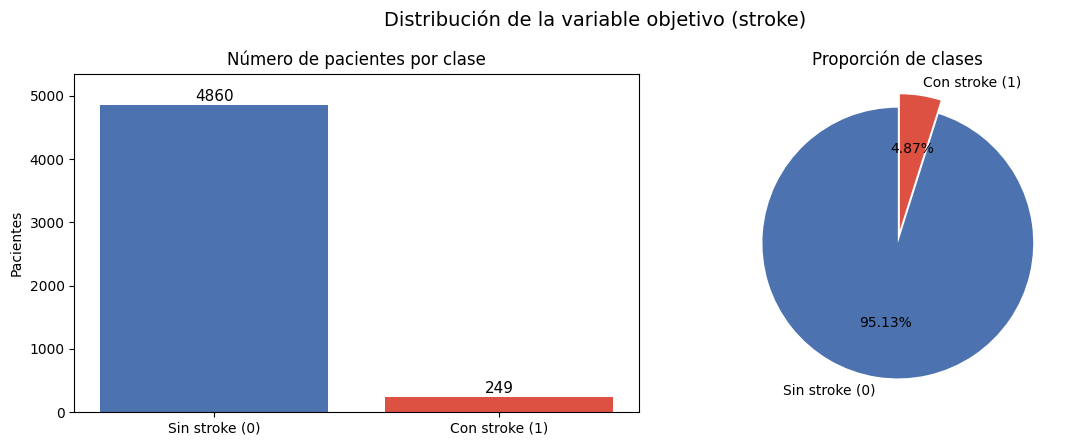

In [26]:
conteo = df_clean['stroke'].value_counts().sort_index()
etiquetas = ['Sin stroke (0)', 'Con stroke (1)']
colores = [COLOR_NO, COLOR_SI]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Gráfico de barras
barras = axes[0].bar(etiquetas, conteo.values, color=colores)
for b, v in zip(barras, conteo.values):
    axes[0].text(b.get_x() + b.get_width()/2, v + 50, f'{v}', ha='center', fontsize=11)
axes[0].set_title('Número de pacientes por clase')
axes[0].set_ylabel('Pacientes')
axes[0].set_ylim(0, conteo.max() * 1.1)

# Gráfico de pastel
axes[1].pie(conteo.values, labels=etiquetas, colors=colores, autopct='%1.2f%%',
            startangle=90, explode=(0, 0.1))
axes[1].set_title('Proporción de clases')

plt.suptitle('Distribución de la variable objetivo (stroke)', fontsize=14)
plt.tight_layout()
plt.show()

**Interpretación:** el dataset está **fuertemente desbalanceado**: solo ≈4.9 % de los pacientes sufrió un derrame (249 de 5,109). Un modelo que siempre prediga "sin stroke" tendría ≈95 % de *accuracy* sin servir para nada, así que en el modelado habrá que usar métricas como *recall*, *F1* o *AUC* y técnicas de balanceo (SMOTE, `class_weight`).

### 2. Histogramas de variables continuas por clase
Se usa `density=True` para comparar la **forma** de las distribuciones; si no, la clase 1 (249 pacientes) quedaría aplastada frente a la clase 0 (4,860).

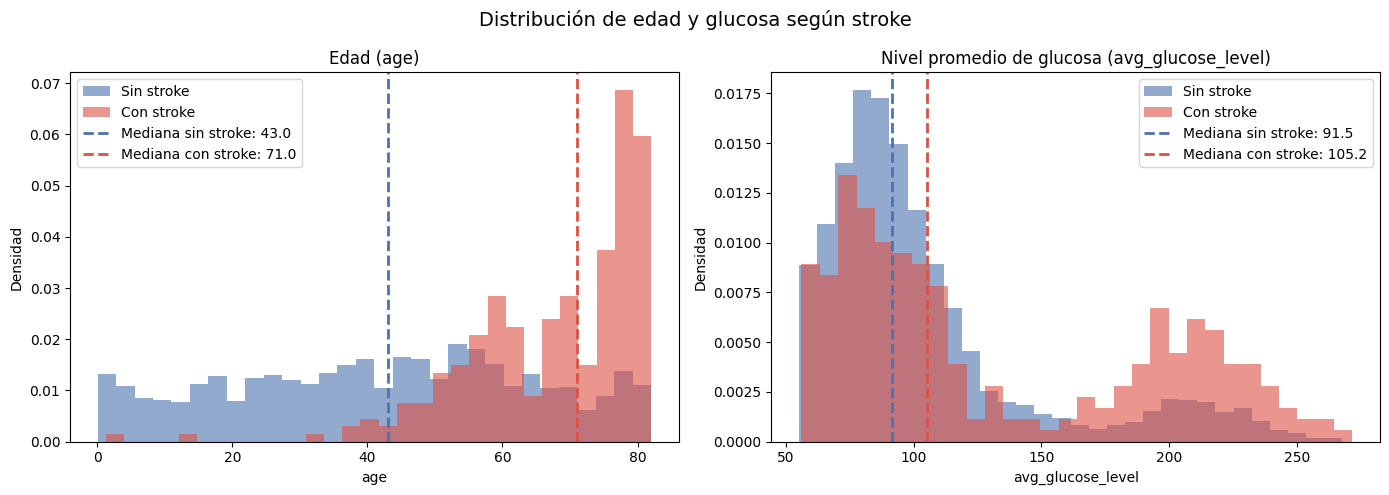

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col, titulo in zip(axes,
                           ['age', 'avg_glucose_level'],
                           ['Edad (age)', 'Nivel promedio de glucosa (avg_glucose_level)']):
    ax.hist(sin_stroke[col], bins=30, alpha=0.6, density=True, color=COLOR_NO, label='Sin stroke')
    ax.hist(con_stroke[col], bins=30, alpha=0.6, density=True, color=COLOR_SI, label='Con stroke')
    ax.axvline(sin_stroke[col].median(), color=COLOR_NO, linestyle='--', linewidth=2,
               label=f'Mediana sin stroke: {sin_stroke[col].median():.1f}')
    ax.axvline(con_stroke[col].median(), color=COLOR_SI, linestyle='--', linewidth=2,
               label=f'Mediana con stroke: {con_stroke[col].median():.1f}')
    ax.set_title(titulo)
    ax.set_xlabel(col)
    ax.set_ylabel('Densidad')
    ax.legend()

plt.suptitle('Distribución de edad y glucosa según stroke', fontsize=14)
plt.tight_layout()
plt.show()

In [28]:
# Resumen numérico que respalda los histogramas
df_clean.groupby('stroke')[['age', 'avg_glucose_level', 'bmi']].agg(['mean', 'median']).round(1)

age        avg_glucose_level          bmi       
        mean median              mean median  mean median
stroke                                                   
0       42.0   43.0             104.8   91.5  28.8   28.1
1       67.7   71.0             132.5  105.2  30.1   28.1

**Interpretación:**
- **Edad:** la diferencia es muy marcada. Los pacientes con stroke tienen una mediana de **71 años** contra **43** en los que no; su distribución se concentra entre los 60 y 80 años, mientras que la de los que no tuvieron derrame es mucho más plana.
- **Glucosa:** ambos grupos tienen un pico alrededor de 80–100, pero los pacientes con stroke presentan un **segundo pico muy notorio entre 190 y 250** (glucosa típica de diabetes). La media sube de 104.8 a 132.5.

### 3. Diagrama de dispersión: edad vs. nivel de glucosa

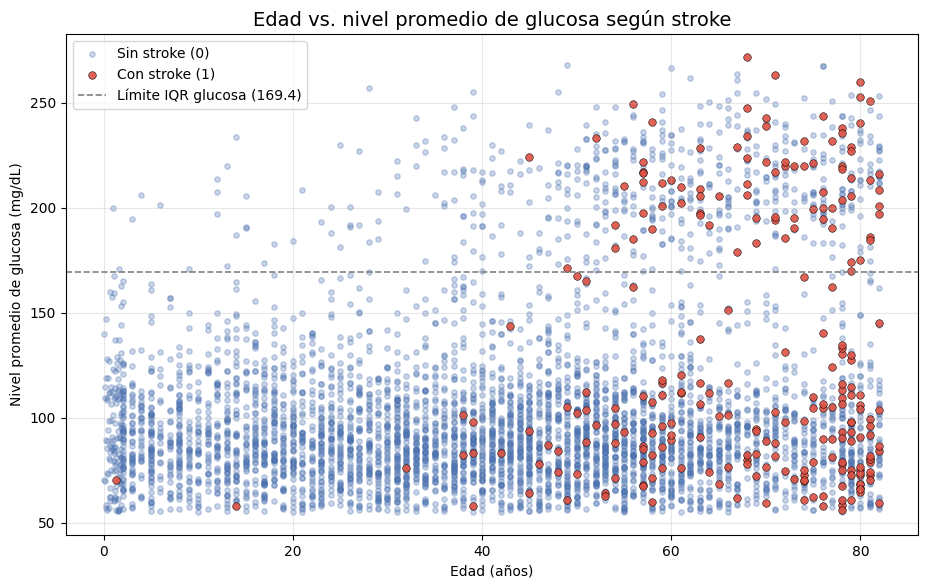

In [29]:
plt.figure(figsize=(11, 6.5))

# Primero la clase 0 y encima la clase 1 para que los casos de stroke no queden tapados
plt.scatter(sin_stroke['age'], sin_stroke['avg_glucose_level'],
            c=COLOR_NO, alpha=0.3, s=15, label='Sin stroke (0)')
plt.scatter(con_stroke['age'], con_stroke['avg_glucose_level'],
            c=COLOR_SI, alpha=0.9, s=30, edgecolors='black', linewidths=0.4, label='Con stroke (1)')

# Límite superior de outliers de glucosa calculado en la Sección 2
plt.axhline(lim_sup, color='gray', linestyle='--', linewidth=1.2,
            label=f'Límite IQR glucosa ({lim_sup:.1f})')

plt.title('Edad vs. nivel promedio de glucosa según stroke', fontsize=14)
plt.xlabel('Edad (años)')
plt.ylabel('Nivel promedio de glucosa (mg/dL)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Interpretación:** los puntos rojos (stroke) se concentran casi por completo en el **lado derecho** (mayores de ~50 años) y son muy escasos en jóvenes. Dentro de ese grupo de edad aparecen tanto con glucosa normal como en la banda alta (> 170), pero la **combinación edad avanzada + glucosa alta** (esquina superior derecha) es donde la densidad de casos de stroke es mayor. El 33.7 % de los pacientes con stroke supera el límite IQR de glucosa, frente a solo 11.2 % de los que no.

### Complemento: tasa de stroke en otros factores de riesgo
No es obligatorio, pero ayuda a sustentar la conclusión con las variables binarias.

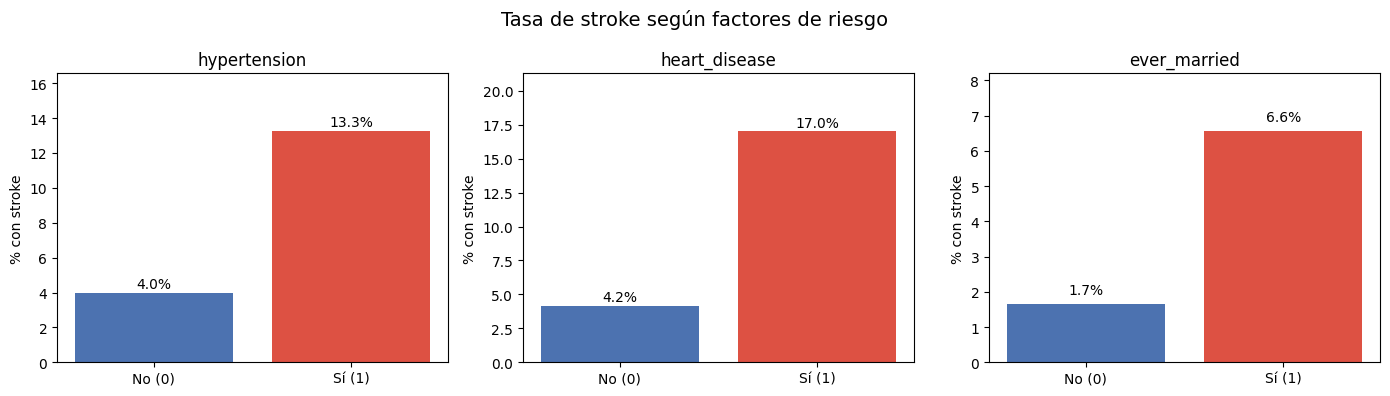

In [30]:
factores = ['hypertension', 'heart_disease', 'ever_married']
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, factores):
    tasa = df_clean.groupby(col)['stroke'].mean() * 100
    barras = ax.bar(['No (0)', 'Sí (1)'], tasa.values, color=[COLOR_NO, COLOR_SI])
    for b, v in zip(barras, tasa.values):
        ax.text(b.get_x() + b.get_width()/2, v + 0.3, f'{v:.1f}%', ha='center')
    ax.set_title(col)
    ax.set_ylabel('% con stroke')
    ax.set_ylim(0, tasa.max() * 1.25)

plt.suptitle('Tasa de stroke según factores de riesgo', fontsize=14)
plt.tight_layout()
plt.show()

In [31]:
# Tasa de stroke por grupo de edad
grupos_edad = pd.cut(df_clean['age'], bins=[0, 40, 60, 100], labels=['0-40', '41-60', '61+'])
(df_clean.groupby(grupos_edad, observed=True)['stroke'].mean() * 100).round(2)

,stroke
age,
0-40,0.36
41-60,4.10
61+,13.57


## 4. Conclusión del EDA

A simple vista, **la edad es el factor de riesgo más determinante**: los pacientes que sufrieron un derrame tienen una mediana de 71 años contra 43 de los que no, y la tasa de stroke pasa de apenas **0.4 %** en menores de 40 años a **13.6 %** en mayores de 60. El segundo factor es el **nivel promedio de glucosa**: su histograma muestra un segundo pico entre 190 y 250 mg/dL en los pacientes con stroke, y en el diagrama de dispersión los casos se concentran en la zona de edad avanzada con glucosa alta, lo que sugiere que ambos factores se potencian. Como complemento, la **hipertensión** (13.3 % vs 4.0 %) y las **enfermedades cardíacas** (17.0 % vs 4.2 %) multiplican entre 3 y 4 veces la tasa de derrame. Variables como `ever_married` también muestran diferencia, pero probablemente es un efecto indirecto de la edad (las personas casadas suelen ser mayores), mientras que el sexo y el tipo de residencia casi no cambian la tasa. Por último, el fuerte desbalance de clases (≈4.9 % positivos) es un punto clave a tratar antes de entrenar cualquier modelo.
